# JobMatch — Machine Learning
## 1. Question de prédiction
Peut-on estimer le milieu de la fourchette salariale d'une offre à partir du métier, de l'expérience et du pays ?
La cible, les prédictions et les métriques de ce notebook restent en **USD**.
Ce n'est pas une prédiction du salaire effectivement versé. Les fonctions sont centralisées dans `src/salary_prediction.py`.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project_root = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / "data/raw/fact_job_postings.csv").is_file()), None)
if project_root is None:
    raise FileNotFoundError("Ouvrez le notebook depuis JobMatch ou son dossier notebooks.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src.salary_prediction import evaluate_salary_model, CORE_FEATURES

data_dir = project_root / "data/raw"
offres = pd.read_csv(data_dir / "fact_job_postings.csv")
liens = pd.read_csv(data_dir / "bridge_job_skills.csv")
pd.options.display.float_format = lambda v: f"{v:,.2f}".replace(",", " ").replace(".", ",")

## 2. Variables X et cible y
**Expérience principale :** X = `job_title`, `experience_level`, `country`.
**y = (salary_min_usd + salary_max_usd) / 2**.
Les identifiants, les bornes salariales et les variables dérivées du salaire sont exclus de X.
Les compétences sont réservées à la comparaison enrichie, avec des indicateurs de présence.

In [2]:
X = offres[CORE_FEATURES].copy()
y = ((offres.salary_min_usd + offres.salary_max_usd) / 2).rename("salary_midpoint_usd")
display(X.head())
display(y.head().to_frame())

,job_title,experience_level,country
0,Senior Data Engineer,Lead,Spain
1,Data Engineer,Mid,India
2,Business Intelligence Analyst,Entry,Netherlands
3,Data Scientist,Lead,Netherlands
4,AI Engineer,Mid,Germany


,salary_midpoint_usd
0,"167 374,00"
1,"149 337,50"
2,"104 598,50"
3,"117 672,00"
4,"174 449,00"


## 3. Nettoyage et protocole d'évaluation
La fonction vérifie les IDs uniques et les bornes numériques, finies, positives et ordonnées.
Les offres à salaire invalide sont exclues et leur nombre est affiché. Les catégories manquantes sont remplacées par « Inconnu ».

Le découpage conserve **80 % pour l'entraînement, 20 % pour le test**, avec `random_state=42`.
Ce choix conserve 44 000 offres pour apprendre et 11 000 pour estimer l'erreur sur des offres non utilisées pour l'entraînement.
Les mêmes IDs sont utilisés pour toutes les configurations. L'encodeur est ajusté sur l'entraînement seulement.
Dans l'expérience enrichie, le vocabulaire de compétences provient aussi de l'entraînement.
Aucun hyperparamètre n'est choisi à partir du test ; il n'y a pas de recherche d'optimisation.

La date ne permet pas de découpage temporel : le test mesure une généralisation au sein du fichier, pas aux offres futures.

## 4. Modèles comparés
- **DummyRegressor, moyenne globale** : référence minimale calculée uniquement sur l'entraînement.
- **Moyenne par métier** : référence plus informative ; un métier inconnu utilise la moyenne globale d'entraînement.
- **Ridge, régression linéaire régularisée** : catégories encodées par OneHotEncoder ; configuration historique enrichie : `alpha=10, solver="lsqr"`.

L'expérience principale utilise les trois variables du sujet et garde `alpha=10` pour isoler le changement de variables.
Deux comparaisons préservent le travail existant : l'ancien modèle enrichi, et le script métier/expérience avec `alpha=1`.

In [3]:
scores, predictions, split = evaluate_salary_model(
    offres, feature_columns=CORE_FEATURES, include_skills=False,
    test_size=0.20, random_state=42, ridge_alpha=10.0, ridge_solver="lsqr", return_split=True)
X_train, X_test = split["X_train"], split["X_test"]
y_train, y_test = split["y_train"], split["y_test"]
print("Offres exclues pour salaire invalide :", split["excluded_salary_rows"])
print("Entraînement :", len(X_train), "— test :", len(X_test))
print("IDs communs :", len(set(X_train.index) & set(X_test.index)))
assert set(X_train.index).isdisjoint(X_test.index)
# Liste fermée : ni salaire, ni composante de la cible, ni identifiant dans X.
assert X_train.columns.tolist() == X_test.columns.tolist() == ["job_title", "experience_level", "country"]
assert np.isclose(len(X_test) / (len(X_train) + len(X_test)), 0.20)
display(X_train.head())
display(y_train.head().to_frame())

Offres exclues pour salaire invalide : 0
Entraînement : 44000 — test : 11000
IDs communs : 0


,job_title,experience_level,country
job_id,,,
JOB-24726,Data Engineer,Entry,France
JOB-66,AI Engineer,Mid,Singapore
JOB-52497,Data Scientist,Senior,Netherlands
JOB-36591,Business Intelligence Analyst,Entry,India
JOB-24398,Data Analyst,Senior,Singapore


,salary_midpoint_usd
job_id,
JOB-24726,"106 970,50"
JOB-66,"144 054,00"
JOB-52497,"102 647,00"
JOB-36591,"71 515,00"
JOB-24398,"89 893,50"


## 5. Comparaisons des configurations existantes
L'expérience enrichie reproduit les variables et hyperparamètres des anciens notebooks :
métier, pays, expérience, mode de travail, contrat et compétences, Ridge alpha=10 avec lsqr.
Le script le plus récent utilisait seulement métier/expérience et Ridge alpha=1 avec le solveur automatique ;
sa configuration est conservée séparément. Ces comparaisons ne servent pas à régler le modèle sur le test.

In [4]:
scores_enrichis, predictions_enrichies = evaluate_salary_model(offres, liens)
scores_historiques, predictions_historiques = evaluate_salary_model(
    offres, feature_columns=["job_title", "experience_level"], include_skills=False,
    ridge_alpha=1.0, ridge_solver="auto")
assert predictions.job_id.tolist() == predictions_enrichies.job_id.tolist() == predictions_historiques.job_id.tolist()
comparaison = pd.concat({
    "Principal : métier, expérience, pays (alpha=10)": scores,
    "Historique enrichi (alpha=10)": scores_enrichis,
    "Script métier/expérience (alpha=1)": scores_historiques,
}, names=["configuration", "modele"])
# Les deux références sont identiques entre configurations ; montrer ici uniquement Ridge.
display(comparaison.xs("Regression Ridge", level="modele"))

,MAE_USD,RMSE_USD,R2,n_train,n_test
configuration,,,,,
"Principal : métier, expérience, pays (alpha=10)","17 867,75","21 320,21","0,67",44000,11000
Historique enrichi (alpha=10),"17 872,05","21 325,90","0,67",44000,11000
Script métier/expérience (alpha=1),"17 870,14","21 319,83","0,67",44000,11000


## 6. Métriques et comparaison des modèles
**MAE (USD)** : erreur absolue moyenne, retenue comme métrique principale.
**RMSE (USD)** : donne davantage de poids aux grandes erreurs.
**R²**, sans unité : performance relative à la variabilité des cibles du test ; il peut être négatif.
Les trois scores sont calculés sur toutes les offres du test, jamais seulement sur un extrait.

In [5]:
# Contrôles pédagogiques des résultats, complémentaires aux tests automatisés.
modeles_attendus = ["Reference moyenne", "Moyenne par metier", "Regression Ridge"]
assert scores.index.tolist() == modeles_attendus
assert {"MAE_USD", "RMSE_USD", "R2"}.issubset(scores.columns)
assert predictions.job_id.tolist() == X_test.index.tolist()
assert len(predictions) == len(y_test)
assert np.isfinite(predictions[modeles_attendus + ["salaire_cible_usd"]].to_numpy()).all()
assert np.isfinite(scores[["MAE_USD", "RMSE_USD", "R2"]].to_numpy()).all()
assert scores[["MAE_USD", "RMSE_USD"]].ge(0).all().all()

print("Expérience principale :")
display(scores)
mae = scores["MAE_USD"]
print(f"Réduction de MAE de Ridge / moyenne globale : {100 * (1 - mae['Regression Ridge']/mae['Reference moyenne']):.2f} %")
print(f"Écart de MAE de Ridge / moyenne par métier : {mae['Regression Ridge'] - mae['Moyenne par metier']:.2f} USD")
recalcul_mae = pd.Series({
    m: (predictions[m] - predictions.salaire_cible_usd).abs().mean() for m in scores.index}, name="MAE_recalculee_USD")
np.testing.assert_allclose(recalcul_mae.loc[scores.index], scores.MAE_USD)
print("Vérifications validées : prédictions finies et alignées, métriques présentes, MAE recalculées cohérentes.")

Expérience principale :


,MAE_USD,RMSE_USD,R2,n_train,n_test
modele,,,,,
Reference moyenne,"31 452,33","36 998,20","-0,00",44000,11000
Moyenne par metier,"17 870,60","21 318,46","0,67",44000,11000
Regression Ridge,"17 867,75","21 320,21","0,67",44000,11000


Réduction de MAE de Ridge / moyenne globale : 43.19 %
Écart de MAE de Ridge / moyenne par métier : -2.85 USD
Vérifications validées : prédictions finies et alignées, métriques présentes, MAE recalculées cohérentes.


## 7. Analyse des erreurs

Exemples : cible = milieu de la fourchette, pas salaire effectivement versé.


,job_id,salaire_cible_usd,Reference moyenne,Moyenne par metier,Regression Ridge,job_title,experience_level,country,erreur_Reference moyenne,absolue_Reference moyenne,erreur_Moyenne par metier,absolue_Moyenne par metier,erreur_Regression Ridge,absolue_Regression Ridge
0,JOB-34192,"125 157,50","121 996,25","125 450,04","125 410,06",Senior Data Scientist,Lead,UAE,"-3 161,25","3 161,25","292,54","292,54","252,56","252,56"
1,JOB-23680,"93 159,50","121 996,25","77 597,53","77 782,74",Business Intelligence Analyst,Entry,Netherlands,"28 836,75","28 836,75","-15 561,97","15 561,97","-15 376,76","15 376,76"
2,JOB-44685,"126 725,50","121 996,25","124 693,29","125 322,38",Data Scientist,Senior,United States,"-4 729,25","4 729,25","-2 032,21","2 032,21","-1 403,12","1 403,12"
3,JOB-11336,"146 559,00","121 996,25","124 693,29","124 549,80",Data Scientist,Senior,Spain,"-24 562,75","24 562,75","-21 865,71","21 865,71","-22 009,20","22 009,20"
4,JOB-22692,"184 421,50","121 996,25","147 485,24","147 687,54",Data Engineer,Mid,Singapore,"-62 425,25","62 425,25","-36 936,26","36 936,26","-36 733,96","36 733,96"
5,JOB-32405,"115 737,50","121 996,25","147 819,59","147 660,71",AI Engineer,Lead,Australia,"6 258,75","6 258,75","32 082,09","32 082,09","31 923,21","31 923,21"
6,JOB-53453,"103 650,00","121 996,25","125 450,04","125 896,37",Senior Data Scientist,Mid,UAE,"18 346,25","18 346,25","21 800,04","21 800,04","22 246,37","22 246,37"
7,JOB-50290,"163 217,00","121 996,25","147 030,34","147 611,76",Machine Learning Engineer,Mid,United States,"-41 220,75","41 220,75","-16 186,66","16 186,66","-15 605,24","15 605,24"
8,JOB-587,"109 526,00","121 996,25","147 819,59","147 783,56",AI Engineer,Entry,Ireland,"12 470,25","12 470,25","38 293,59","38 293,59","38 257,56","38 257,56"
9,JOB-23901,"96 602,00","121 996,25","125 450,04","125 278,47",Senior Data Scientist,Lead,Canada,"25 394,25","25 394,25","28 848,04","28 848,04","28 676,47","28 676,47"


job_title


,nombre_offres,MAE_Ridge_USD,MAE_globale_USD,MAE_metier_USD
job_title,,,,
AI Engineer,1145,"21 543,53","29 528,88","21 529,49"
Analytics Engineer,1068,"20 818,02","28 853,05","20 851,21"
Business Intelligence Analyst,1159,"11 851,63","44 294,41","11 875,03"
Data Analyst,1074,"11 871,34","43 885,46","11 880,76"
Data Engineer,1086,"21 642,41","29 364,97","21 638,76"
Data Scientist,1049,"17 757,34","17 878,40","17 745,84"
Machine Learning Engineer,1077,"21 515,87","29 772,48","21 500,82"
Senior Data Analyst,1088,"11 762,59","44 262,78","11 770,53"
Senior Data Engineer,1081,"21 897,27","28 229,05","21 913,41"


experience_level


,nombre_offres,MAE_Ridge_USD,MAE_globale_USD,MAE_metier_USD
experience_level,,,,
Entry,2760,"17 775,94","31 332,72","17 780,98"
Lead,2784,"17 948,74","31 214,92","17 947,09"
Mid,2743,"17 614,85","31 132,48","17 619,69"
Senior,2713,"18 133,76","32 141,03","18 136,98"


country


,nombre_offres,MAE_Ridge_USD,MAE_globale_USD,MAE_metier_USD
country,,,,
Australia,884,"17 405,07","31 715,21","17 423,01"
Brazil,840,"18 281,40","32 094,85","18 304,61"
Canada,823,"17 655,73","30 752,89","17 665,46"
France,888,"17 581,42","31 387,70","17 592,24"
Germany,867,"17 693,90","31 152,46","17 702,36"
India,841,"18 653,32","32 189,22","18 644,07"
Ireland,884,"17 505,77","30 081,85","17 505,39"
Netherlands,797,"17 590,85","31 022,76","17 593,08"
Singapore,816,"17 673,54","31 531,13","17 673,70"


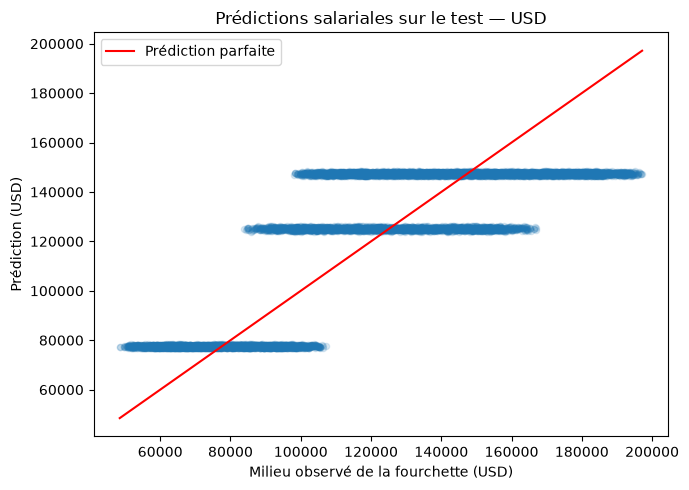

In [6]:
erreurs = predictions.merge(offres[["job_id", "job_title", "experience_level", "country"]],
                            on="job_id", validate="one_to_one")
for modele in scores.index:
    erreurs[f"erreur_{modele}"] = erreurs[modele] - erreurs.salaire_cible_usd
    erreurs[f"absolue_{modele}"] = erreurs[f"erreur_{modele}"].abs()
print("Exemples : cible = milieu de la fourchette, pas salaire effectivement versé.")
display(erreurs.head(10))
for dimension in ["job_title", "experience_level", "country"]:
    print(dimension)
    display(erreurs.groupby(dimension).agg(
        nombre_offres=("job_id", "count"),
        MAE_Ridge_USD=("absolue_Regression Ridge", "mean"),
        MAE_globale_USD=("absolue_Reference moyenne", "mean"),
        MAE_metier_USD=("absolue_Moyenne par metier", "mean")))
erreurs.plot.scatter(x="salaire_cible_usd", y="Regression Ridge", alpha=0.15, figsize=(7, 5))
bornes = [erreurs.salaire_cible_usd.min(), erreurs.salaire_cible_usd.max()]
plt.plot(bornes, bornes, color="red", label="Prédiction parfaite")
plt.xlabel("Milieu observé de la fourchette (USD)")
plt.ylabel("Prédiction (USD)")
plt.title("Prédictions salariales sur le test — USD")
plt.legend()
plt.tight_layout()
plt.show()

## 8. Interprétation et limites
- **Ridge améliore nettement la moyenne globale** : MAE de 17 867,75 USD contre 31 452,33 USD, soit environ 43 % de réduction.
- **Le gain par rapport à la moyenne par métier est très faible** : 2,85 USD de MAE. Le RMSE de Ridge est légèrement supérieur ; aucun avantage pratique marqué n'est établi.
- **Une MAE proche de 17 868 USD reste importante pour une offre individuelle.** La cible est le milieu de la fourchette annoncée, pas un salaire réellement perçu.

Les comparaisons historiques sont conservées dans le tableau de la section 5, sans changement des paramètres.
Les résultats concernent ce fichier et ce découpage aléatoire : ils ne valident ni une généralisation à d'autres sources
ni une prévision temporelle. Les intervalles d'incertitude ne sont pas estimés.

## 9. Reproductibilité et exports
Les données préparées sont conservées en mémoire ; aucun CSV intermédiaire n'est nécessaire.
Le notebook utilise une seule implémentation des modèles et n'exporte rien automatiquement.
Depuis la racine : `python -m src.salary_prediction`.
Pour un export volontaire : `python -m src.salary_prediction --export CHEMIN_DE_SORTIE`.
Les fichiers exportés contiennent des USD. L'application Streamlit existante est un squelette conservé pour une étape ultérieure.

**Exigence de livraison : commit GitHub des corrections finales à effectuer manuellement.**
La préparation et les vérifications techniques ne remplacent pas ce commit. Aucune commande Git n'est exécutée par les notebooks.